In [1]:
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [3]:
df_DA_US = df[(df['job_title_short']=='Data Analyst') & (df['job_country'] == 'United States')].copy()
df_DA_US=df_DA_US.dropna(subset=['salary_year_avg'])
df_DA_US['salary_year_avg'].sample(10)

610625     90000.0
531848     80000.0
588899     83679.0
502111     55000.0
142954    113580.0
750106     90000.0
727158     87500.0
686026     95274.0
217131     52500.0
724255     85600.0
Name: salary_year_avg, dtype: float64

<Axes: >

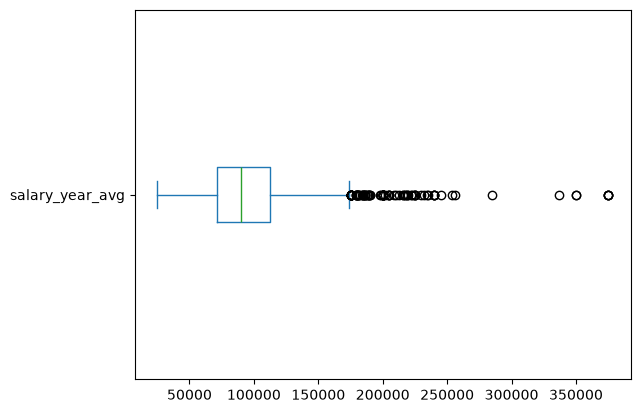

In [6]:
df_DA_US['salary_year_avg'].plot(kind='box',vert=False)

{'whiskers': [<matplotlib.lines.Line2D at 0x2a6369f0cd0>,
 'caps': [<matplotlib.lines.Line2D at 0x2a6369f0f50>,
 'boxes': [<matplotlib.lines.Line2D at 0x2a6369f0b90>],
 'medians': [<matplotlib.lines.Line2D at 0x2a6369f11d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2a6369f1310>],
 'means': []}

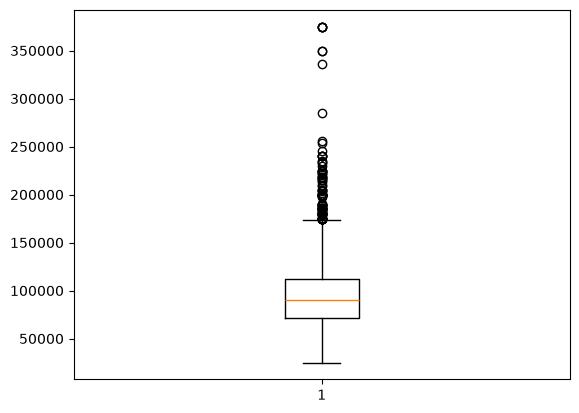

In [5]:
plt.boxplot(df_DA_US['salary_year_avg'])

C:\Users\User\AppData\Local\Temp\ipykernel_32076\3183710607.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(job_list,tick_labels=job_titles, vert=False)


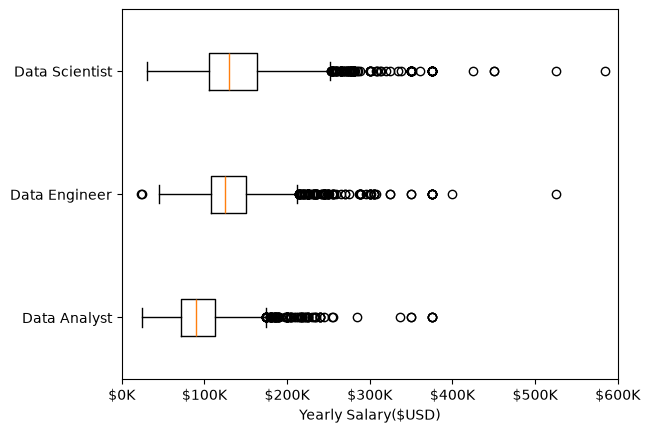

In [25]:
job_titles=['Data Analyst','Data Engineer','Data Scientist']

df_US = df[(df['job_title_short'].isin(job_titles)) & (df['job_country'] == 'United States')].copy()

df_US=df_US.dropna(subset=['salary_year_avg'])
job_list = [df_US[df_US['job_title_short']==job_title]['salary_year_avg']  for job_title in job_titles]

plt.boxplot(job_list,tick_labels=job_titles, vert=False)

plt.xlabel('Yearly Salary($USD)')
ax=plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,pos: f'${int(x/1000)}K'))
plt.xlim(0,600000)
plt.show()
